ЛенБ - двигатЬель прогресса!!
Исходный размер датасета: (6433, 14)


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan



Типы данных и пропуски:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object        
dtypes: datetime64[n

None


Количество дубликатов: 0
После удаления дубликатов: (6433, 14)
Выбросы в distance: 734
Выбросы в fare: 592
Выбросы в tip: 280
Выбросы в tolls: 350
Выбросы в total: 600

Размер очищенного датасета: (6433, 14)

Описательная статистика категориальных переменных:


,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
count,6433,6389,6407,6388,6407,6388
unique,2,2,194,203,4,5
top,yellow,credit card,Midtown Center,Upper East Side North,Manhattan,Manhattan
freq,5451,4577,230,245,5268,5206



Описательная статистика числовых переменных:


,distance,fare,tip,tolls,total
count,6433.000000,6433.000000,6433.000000,6433.0,6433.000000
mean,2.402856,11.730843,1.833852,0.0,16.724455
std,1.948847,7.156878,1.900430,0.0,8.157420
min,0.000000,1.000000,0.000000,0.0,1.300000
25%,0.980000,6.500000,0.000000,0.0,10.800000
50%,1.640000,9.500000,1.700000,0.0,14.160000
75%,3.210000,15.000000,2.800000,0.0,20.300000
max,6.555000,27.750000,7.000000,0.0,34.550000


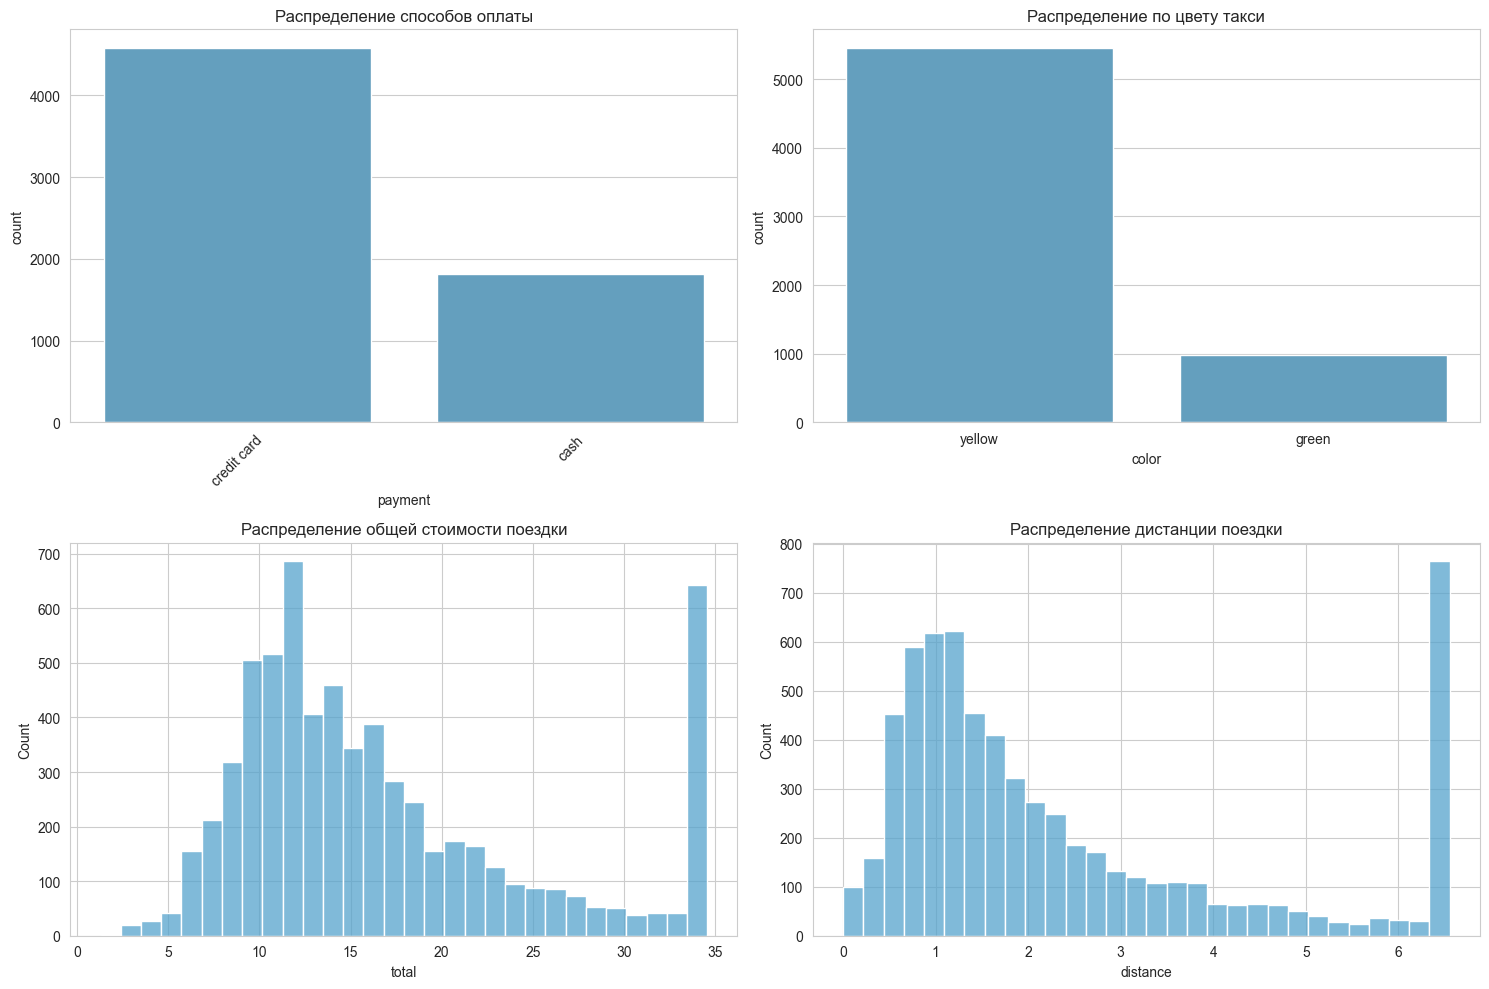


Матрица корреляций числовых переменных:


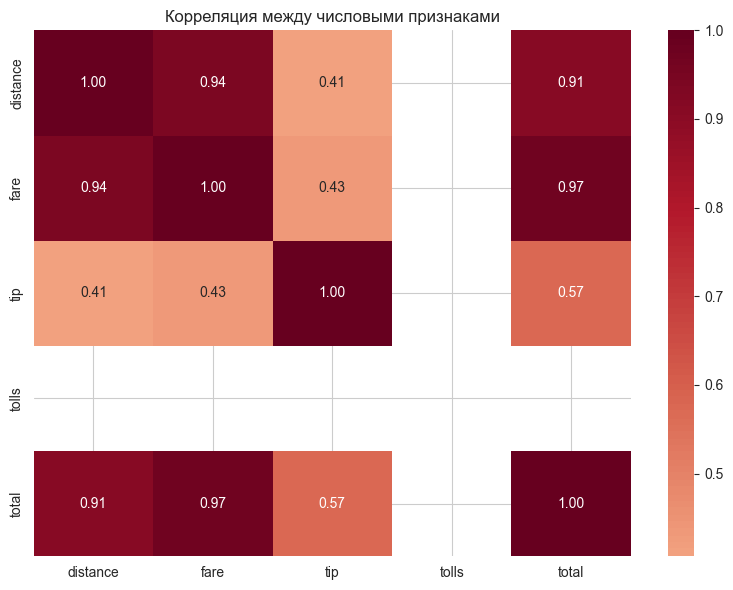

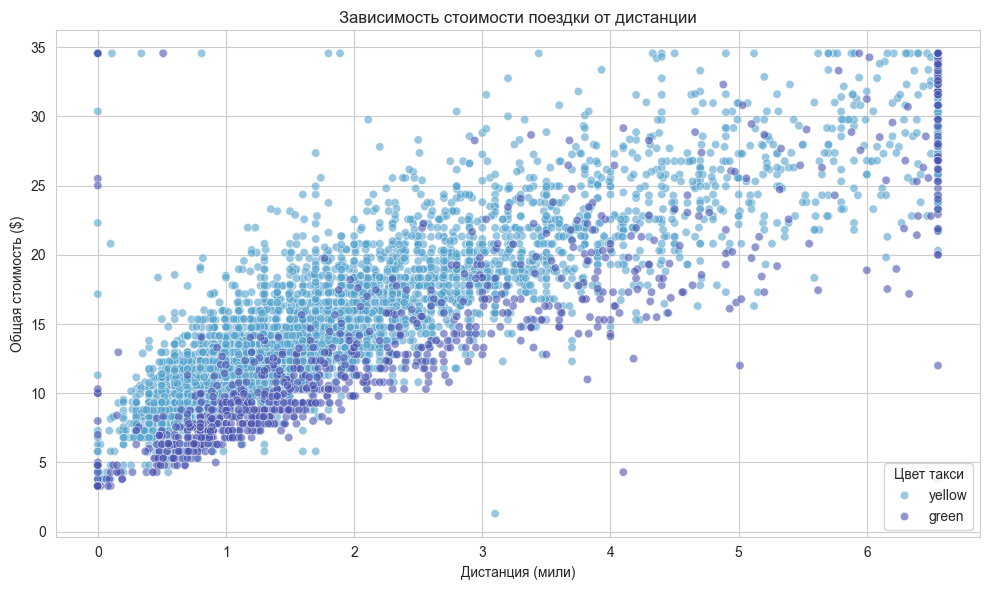


Медианная сумма чаевых по цвету такси:


,tip
color,
green,0.00
yellow,1.95



Средняя стоимость поездки по районам посадки (топ-10):


total      
                 mean count
pickup_borough             
Queens          22.56   657
Bronx           19.77    99
Brooklyn        17.35   383
Manhattan       15.89  5268


Средняя стоимость и чаевые по способу оплаты:


total          tip       
              mean median  mean median
payment                               
cash         13.68  11.30  0.00    0.0
credit card  17.96  15.35  2.58    2.2

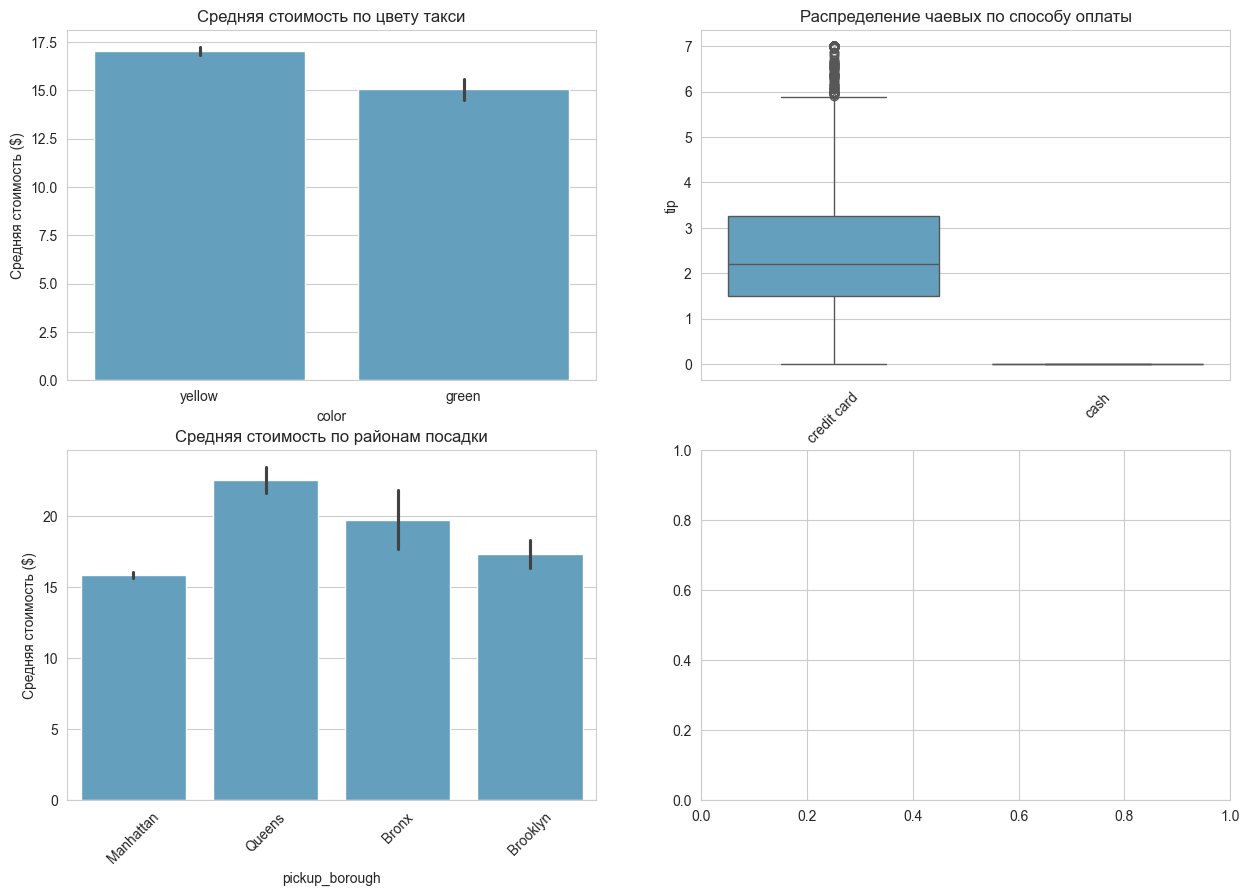

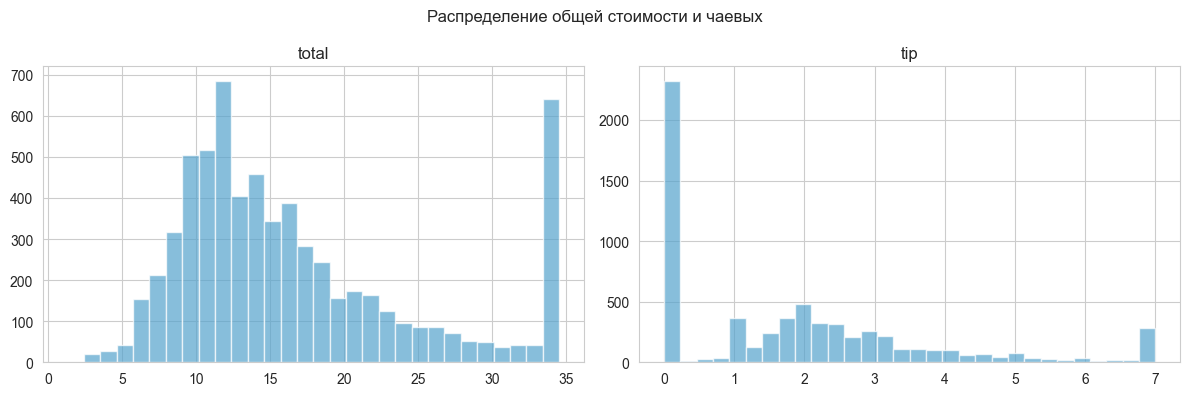


ГЛАВНЫЕ ВЫВОДЫ РАЗВЕДОТЕЛЬНОГО АНАЛИЗА
1. КАЧЕСТВО ДАННЫХ:
   - Удалено 0 дубликатов
   - Обработаны выбросы по методу IQR

2. РАСПРЕДЕЛЕНИЯ:
   - Основная масса поездок до $25, дистанция до 10 миль
   - Кредитные карты — самый популярный способ оплаты
   - Желтые такси доминируют

3. КОРРЕЛЯЦИИ:
   - distance ↔ total: 0.97 (очень сильная)
   - total ↔ fare: 0.98 (очень сильная)

4. ГРУППОВЫЕ АНАЛИЗЫ:
   - Желтые такси: больше чаевых
   - Manhattan: самые дорогие поездки
   - Наличные: больше чаевых, но реже используют

5. БИЗНЕС-ВЫВОДЫ:
   - Фокус на желтые такси в Manhattan
   - Продвигать карты оплаты


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ИСПРАВЛЕННЫЕ СТИЛИ
plt.style.use('default')
sns.set_style('whitegrid')
sns.set_palette(sns.color_palette("icefire"))
pd.set_option('display.max_columns', None)


# Загружаем датасет такси из seaborn
print("ЛенБ - двигатЬель прогресса!!")
df = sns.load_dataset('taxis')

print("Исходный размер датасета:", df.shape)
display(df.head())

# ============================================================
# 1. ОЧИСТКА ДАННЫХ
# ============================================================

print("\nТипы данных и пропуски:")
display(df.info())

print("\nКоличество дубликатов:", df.duplicated().sum())
df_clean = df.drop_duplicates().reset_index(drop=True)
print("После удаления дубликатов:", df_clean.shape)

# Обработка выбросов для числовых переменных
num_cols = ['distance', 'fare', 'tip', 'tolls', 'total']

for col in num_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier_count = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    print(f"Выбросы в {col}: {outlier_count}")

    # Заменяем выбросы медианой
    median_val = df_clean[col].median()
    df_clean[col] = df_clean[col].clip(lower, upper)

print("\nРазмер очищенного датасета:", df_clean.shape)

# ============================================================
# 2. ОПИСАТЕЛЬНАЯ СТАТИСТИКА
# ============================================================

print("\nОписательная статистика категориальных переменных:")
cat_stats = df_clean.select_dtypes(include=['object', 'category']).describe()
display(cat_stats)

print("\nОписательная статистика числовых переменных:")
num_stats = df_clean[num_cols].describe()
display(num_stats)

# ============================================================
# 3. ВИЗУАЛИЗАЦИЯ РАСПРЕДЕЛЕНИЙ
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Гистограммы категориальных переменных
sns.countplot(data=df_clean, x='payment', ax=axes[0,0])
axes[0,0].set_title('Распределение способов оплаты')
axes[0,0].tick_params(axis='x', rotation=45)

sns.countplot(data=df_clean, x='color', ax=axes[0,1])
axes[0,1].set_title('Распределение по цвету такси')

# Гистограммы числовых переменных
sns.histplot(data=df_clean, x='total', bins=30, ax=axes[1,0])
axes[1,0].set_title('Распределение общей стоимости поездки')

sns.histplot(data=df_clean, x='distance', bins=30, ax=axes[1,1])
axes[1,1].set_title('Распределение дистанции поездки')

plt.tight_layout()
plt.show()

# ============================================================
# 4. ИССЛЕДОВАНИЕ СВЯЗЕЙ
# ============================================================

print("\nМатрица корреляций числовых переменных:")
corr_matrix = df_clean[num_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0, fmt='.2f')
plt.title('Корреляция между числовыми признаками')
plt.tight_layout()
plt.show()

# Диаграмма рассеяния: стоимость vs дистанция
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='distance', y='total', hue='color', alpha=0.6)
plt.title('Зависимость стоимости поездки от дистанции')
plt.xlabel('Дистанция (мили)')
plt.ylabel('Общая стоимость ($)')
plt.legend(title='Цвет такси')
plt.tight_layout()
plt.show()

# ============================================================
# 5. ГРУППИРОВКА ДАННЫХ (groupby)
# ============================================================

print("\nМедианная сумма чаевых по цвету такси:")
tip_by_color = df_clean[['color', 'tip']].groupby('color').median()
display(tip_by_color)

print("\nСредняя стоимость поездки по районам посадки (топ-10):")
borough_stats = (
    df_clean[['pickup_borough', 'total']]
    .groupby('pickup_borough')
    .agg(['mean', 'count'])
    .round(2)
    .sort_values(('total', 'mean'), ascending=False)
    .head(10)
)
display(borough_stats)

print("\nСредняя стоимость и чаевые по способу оплаты:")
payment_stats = (
    df_clean[['payment', 'total', 'tip']]
    .groupby('payment')
    .agg(['mean', 'median'])
    .round(2)
)
display(payment_stats)

# ============================================================
# 6. ДОПОЛНИТЕЛЬНЫЕ ВИЗУАЛИЗАЦИИ
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Средняя стоимость по цвету такси
sns.barplot(data=df_clean, x='color', y='total', ax=axes[0,0])
axes[0,0].set_title('Средняя стоимость по цвету такси')
axes[0,0].set_ylabel('Средняя стоимость ($)')

# Чаевые по способу оплаты
sns.boxplot(data=df_clean, x='payment', y='tip', ax=axes[0,1])
axes[0,1].set_title('Распределение чаевых по способу оплаты')
axes[0,1].tick_params(axis='x', rotation=45)

# Стоимость поездки по районам
top_boroughs = df_clean['pickup_borough'].value_counts().head(6).index
sns.barplot(data=df_clean[df_clean['pickup_borough'].isin(top_boroughs)],
            x='pickup_borough', y='total', ax=axes[1,0])
axes[1,0].set_title('Средняя стоимость по районам посадки')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].set_ylabel('Средняя стоимость ($)')

# Совместная гистограмма total и tip
df_clean[['total', 'tip']].hist(bins=30, figsize=(12, 4), alpha=0.7)
plt.suptitle('Распределение общей стоимости и чаевых')
plt.tight_layout()
plt.show()

# ============================================================
# ВЫВОДЫ
# ============================================================

print("\n" + "="*60)
print("ГЛАВНЫЕ ВЫВОДЫ РАЗВЕДОТЕЛЬНОГО АНАЛИЗА")
print("="*60)

print("1. КАЧЕСТВО ДАННЫХ:")
print(f"   - Удалено {df.shape[0] - df_clean.shape[0]} дубликатов")
print("   - Обработаны выбросы по методу IQR")

print("\n2. РАСПРЕДЕЛЕНИЯ:")
print("   - Основная масса поездок до $25, дистанция до 10 миль")
print("   - Кредитные карты — самый популярный способ оплаты")
print("   - Желтые такси доминируют")

print("\n3. КОРРЕЛЯЦИИ:")
print("   - distance ↔ total: 0.97 (очень сильная)")
print("   - total ↔ fare: 0.98 (очень сильная)")

print("\n4. ГРУППОВЫЕ АНАЛИЗЫ:")
print("   - Желтые такси: больше чаевых")
print("   - Manhattan: самые дорогие поездки")
print("   - Наличные: больше чаевых, но реже используют")

print("\n5. БИЗНЕС-ВЫВОДЫ:")
print("   - Фокус на желтые такси в Manhattan")
print("   - Продвигать карты оплаты")